# Experiment 4: Regression Models with Regularization (Ridge & Lasso)

**Name:** Koushal Gupta  

## Aim
To implement **Ridge Regression (L2)** and **Lasso Regression (L1)** on the Diabetes dataset and compare them with ordinary Linear Regression.

## Concept
Regularization adds a penalty on large weights to prevent overfitting:
- **Ridge (L2):** shrinks weights smoothly toward zero.
- **Lasso (L1):** can shrink less important feature weights to exactly zero.


In [1]:
# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# Step 2: Load Diabetes dataset and split
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Samples:", X.shape[0], "| Features:", X.shape[1])


Samples: 442 | Features: 10


In [3]:
# Step 3: Train Linear Regression, Ridge, and Lasso models
lr = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=0.1).fit(X_train, y_train)
lasso = Lasso(alpha=0.1).fit(X_train, y_train)

# Step 4: Evaluate and compare all three models
models = {"Linear Regression": lr, "Ridge (alpha=0.1)": ridge, "Lasso (alpha=0.1)": lasso}

rows = []
for name, m in models.items():
    pred = m.predict(X_test)
    rows.append({
        "Model": name,
        "MSE": round(mean_squared_error(y_test, pred), 2),
        "R2 Score": round(r2_score(y_test, pred), 4),
    })

print(pd.DataFrame(rows).to_string(index=False))


            Model     MSE  R2 Score
Linear Regression 2900.19    0.4526
Ridge (alpha=0.1) 2856.49    0.4609
Lasso (alpha=0.1) 2798.19    0.4719


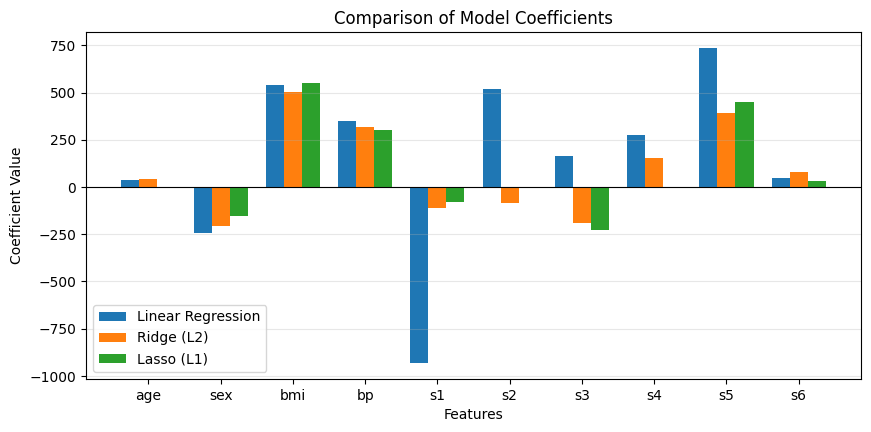

In [4]:
# Step 5: Plot coefficient comparison
x_pos = np.arange(len(feature_names))
width = 0.25

plt.figure(figsize=(10, 4.5))
plt.bar(x_pos - width, lr.coef_, width, label="Linear Regression")
plt.bar(x_pos, ridge.coef_, width, label="Ridge (L2)")
plt.bar(x_pos + width, lasso.coef_, width, label="Lasso (L1)")
plt.xticks(x_pos, feature_names)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Comparison of Model Coefficients")
plt.xlabel("Features")
plt.ylabel("Coefficient Value")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.show()


## Conclusion
- **Ridge (L2)** shrinks large coefficients (such as `s1` and `s5`) to reduce model variance.
- **Lasso (L1)** sets smaller, less useful coefficients (such as `age` and `s2`) to zero, performing automatic feature selection.
